In [1]:
import glob
import os
import json

import numpy as np
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
from ultralytics import YOLO
import pandas as pd

import sys
sys.path.append("../objectdetectionmetrics/")
from metricsevaluator import MetricsEvaluator
import utils

pd.options.display.float_format = '{:.3f}'.format
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
pd.set_option('max_colwidth', 1000)

In [10]:
TUNED_CONF_TH = 0.3
TUNED_IOU_TH = 0.5

INPUT_WIDTH = 320
INPUT_HEIGHT = 320

BASE_DATASET_PTH = "/home/klymy/data/people_detection/filtered_v3_margin_10"
SUBSET_NAME = "algotest"

IMGS_PTH = os.path.join(BASE_DATASET_PTH, "images", SUBSET_NAME)
LABELS_PTH = os.path.join(BASE_DATASET_PTH, "labels", SUBSET_NAME)

DATASET_PTH = os.path.join(BASE_DATASET_PTH, "project_algotest.yaml")

WEIGHTS_PTH = "results/filtered_v2/weights/best.pt"

PROJECT = os.path.join(os.getcwd(), "val")
EXP_NAME = "algotest_pose"
PREDICTIONS_PTH = os.path.join(PROJECT, EXP_NAME, "predictions.json")

model = YOLO(WEIGHTS_PTH)

In [11]:
# font 
font = cv2.FONT_HERSHEY_SIMPLEX 
  
# fontScale 
fontScale = 0.85
  
# Line thickness of 2 px 
thickness = 3

colors = {
    utils.BBType.GroundTruth: (0, 255, 0),
    utils.BBType.Detected: (0, 0, 255)
}

In [4]:
if not os.path.exists(PREDICTIONS_PTH):
    metrics = model.val(
        data=DATASET_PTH,
        task="pose",
        device=[2],
        batch=64,
        verbose=True,
        conf=TUNED_CONF_TH,
        iou=TUNED_IOU_TH,
        project=PROJECT,
        name=EXP_NAME,
        exist_ok=True,
        save_json=True,
    )


with open(PREDICTIONS_PTH, "rt") as f:
    predictions = json.load(f)

In [5]:
def plot_img(img_id:str, predictions: dict[str, list]) -> np.ndarray:
    img = cv2.imread(os.path.join(IMGS_PTH, f"{img_id}.jpg"))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_h, img_w, _ = img.shape
    
    color = colors[utils.BBType.GroundTruth]
    label_pth = os.path.join(LABELS_PTH, f"{img_id}.txt")
    with open(label_pth, "rt") as f:
        lines = f.readlines()
    for line in lines:
        _, x_c, y_c, w, h, x, y = [float(i) for i in line[:-1].split()]
        
        p1 = [int((x_c - w / 2) * img_w), int((y_c - h / 2) * img_h)]
        p2 = [int((x_c + w / 2) * img_w), int((y_c + h / 2) * img_h)]
        point = [int(x * img_w), int(y * img_h)]
        cv2.rectangle(img, p1, p2, color, 2)
        cv2.circle(img, point, 6, color, 10)
        
        


    color = colors[utils.BBType.Detected]
    for prediction in predictions[img_id]:
        bbox = np.array(prediction["bbox"]).astype(int)
        
        cv2.rectangle(img, bbox[:2], bbox[:2] + bbox[2:], color, 2)
        
        point = np.array(prediction["keypoints"]).astype(int)
        cv2.circle(img, point, 6, color, 10)
        
        cv2.rectangle(img, bbox[:2], bbox[:2] + [75, 40], color, -1)
        cv2.putText(img, f"{prediction['score']:.02f}", bbox[:2] + [5, 25], font, fontScale, (255, 255, 255), thickness, cv2.LINE_AA) 

    return img

In [6]:
predictions_by_id = {}
for prediction in predictions:
    img_id = prediction["image_id"]
    if img_id in predictions_by_id:
        predictions_by_id[img_id].append(prediction)
    else:
        predictions_by_id[img_id] = [prediction]

len(predictions_by_id)

9189

In [7]:
metrics_pth = os.path.join(PROJECT, EXP_NAME, "metrics_per_img.csv")

if os.path.exists(metrics_pth):
    metrics = pd.read_csv(metrics_pth)
else:

    # init evaluator
    img_sizes: dict[str, tuple] = {}

    metrics = []

    common_evaluator = MetricsEvaluator(
            is_relative_coordinates=True,
            is_xywh_coordinates=True,
            img_size=(INPUT_WIDTH, INPUT_HEIGHT),
            outpath="."
        )

    for img_id, predictions in tqdm(predictions_by_id.items(), total=len(predictions_by_id)):
        evaluator = MetricsEvaluator(
            is_relative_coordinates=True,
            is_xywh_coordinates=True,
            img_size=(INPUT_WIDTH, INPUT_HEIGHT),
            outpath="."
        )

        img_size = img_sizes.get(img_id, None)
        if img_size is None:
            img = cv2.imread(os.path.join(IMGS_PTH, f"{img_id}.jpg"))
            img_h, img_w, _ = img.shape
            img_sizes[img_id] = (img_h, img_w)
        else:
            img_h, img_w = img_size

        label_pth = os.path.join(LABELS_PTH, f"{img_id}.txt")
        with open(label_pth, "rt") as f:
            lines = f.readlines()
        for line in lines:
            c, x_c, y_c, w, h = [float(i) for i in line[:-1].split()][:5]
            if c > 1:
                continue
            if np.isnan(x_c):
                continue
            
            evaluator.add_gt_box(
                img_path=img_id,
                class_name="person",
                bbox=[x_c, y_c, w, h]
            )
            common_evaluator.add_gt_box(
                img_path=img_id,
                class_name="person",
                bbox=[x_c, y_c, w, h]
            )

        for prediction in predictions:
            x, y, w, h = np.array(prediction["bbox"]) / [img_w, img_h, img_w, img_h]

            evaluator.add_det_box(
                img_path=img_id,
                class_name="person",
                bbox=[x + w/2, y + h/2, w, h],
                confidence=prediction["score"]
            )
            common_evaluator.add_det_box(
                img_path=img_id,
                class_name="person",
                bbox=[x + w/2, y + h/2, w, h],
                confidence=prediction["score"]
            )


        result = evaluator.eval_conf_vals(0.5)[0]
        precision = result["total TP"] / (result["total TP"] + result["total FP"])
        recall = result["total TP"] / (result["total positives"])
        f_score = 2 * precision * recall / (precision + recall + 1e-9)
        metrics.append({
            "img_id": img_id,
            "P": precision,
            "R": recall,
            "F1": f_score,
            "AP": result['AP']
        })

    metrics = pd.DataFrame(metrics)
    metrics.to_csv(metrics_pth, index=False)

    results = common_evaluator.eval_conf_vals(0.5)
    for result in results:
        precision = result["total TP"] / (result["total TP"] + result["total FP"])
        recall = result["total TP"] / (result["total positives"])

        f_score = 2 * precision * recall / (precision + recall)
        print(f"{result['class']}: P = {precision:.03f}. R = {recall:.03f}. F1 = {f_score:.03f}. AP = {result['AP']:.03f}")

print("=============================================")
print(metrics.head())
print("=============================================")
print("Avg:")
print(metrics[["P", "R", "F1", "AP"]].mean())

                                                         img_id     P     R    F1    AP
0  ILoffice_H250_Cam2_MR_VLC_4HO_10fps_r1_20220607_143207_00100 0.500 0.500 0.500 0.500
1                PG1_Q_H300_Batzra_empty_11_11_34_03_2016_01400 1.000 0.800 0.889 0.800
2                PG1_Q_H300_Batzra_empty_11_11_34_03_2016_01500 1.000 0.700 0.824 0.700
3                PG1_Q_H300_Batzra_empty_11_11_34_03_2016_01600 0.875 0.778 0.824 0.778
4                PG1_Q_H300_Batzra_empty_11_11_34_03_2016_01700 1.000 0.900 0.947 0.900
Avg:
P    0.905
R    0.867
F1   0.877
AP   0.844
dtype: float64


In interval (-0.1, 0.0] number of cases =   84 ( 0.9%)
In interval ( 0.0, 0.1] number of cases =    0 ( 0.0%)
In interval ( 0.1, 0.2] number of cases =   21 ( 0.2%)
In interval ( 0.2, 0.3] number of cases =   48 ( 0.5%)
In interval ( 0.3, 0.4] number of cases =  120 ( 1.3%)
In interval ( 0.4, 0.5] number of cases =  226 ( 2.5%)
In interval ( 0.5, 0.6] number of cases =  175 ( 1.9%)
In interval ( 0.6, 0.7] number of cases =  546 ( 5.9%)
In interval ( 0.7, 0.8] number of cases = 1091 (11.9%)
In interval ( 0.8, 0.9] number of cases = 1344 (14.6%)
In interval ( 0.9, 1.0] number of cases = 5426 (59.0%)


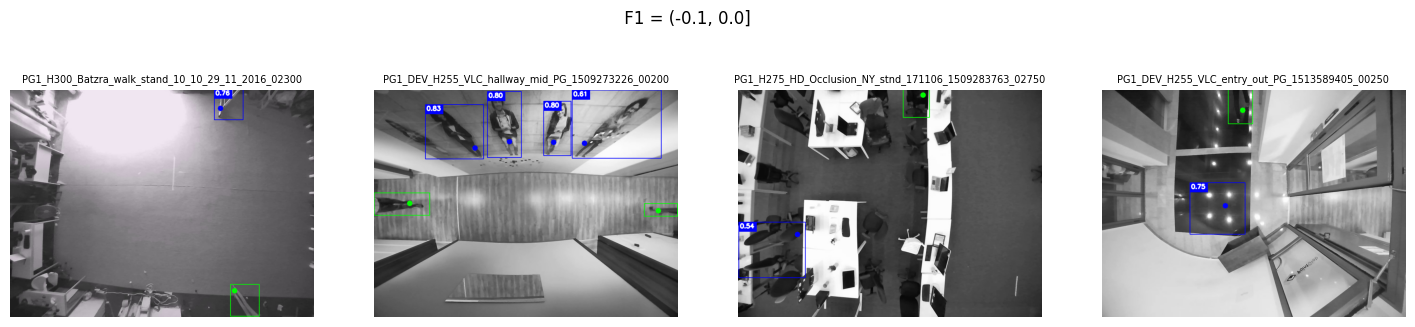

<Figure size 1800x400 with 0 Axes>

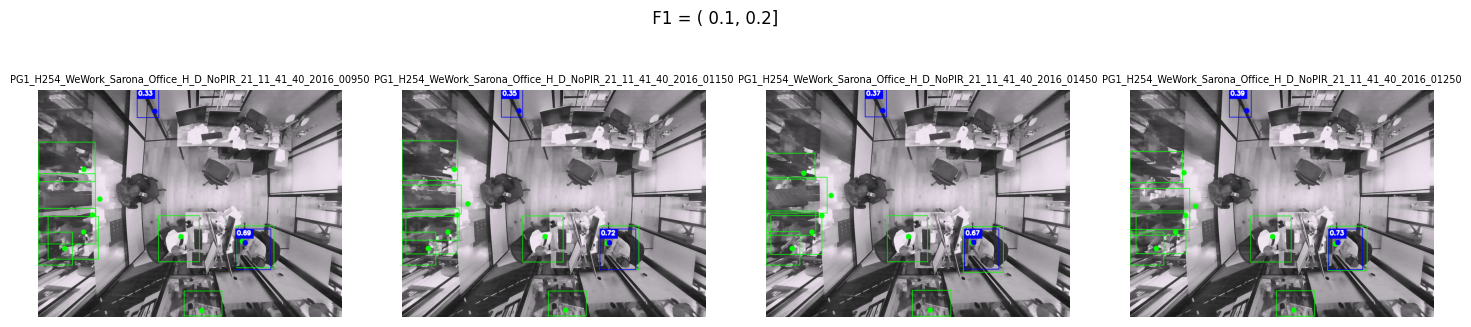

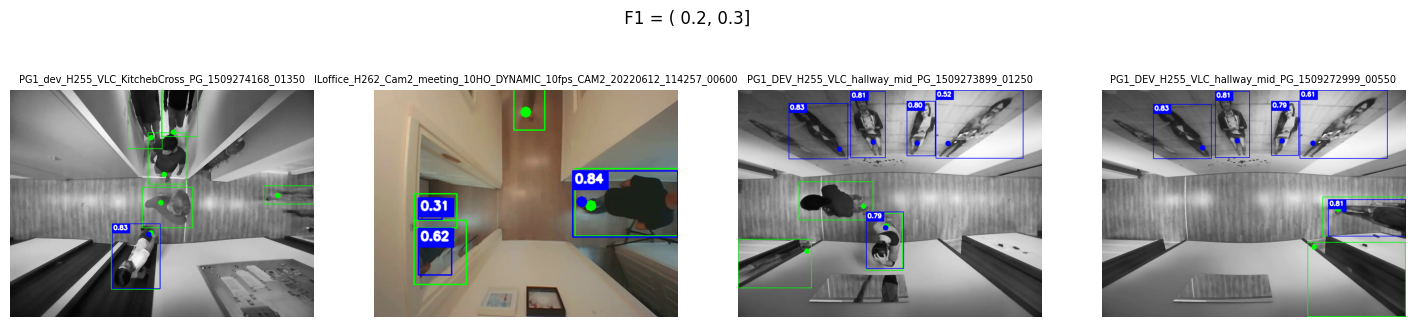

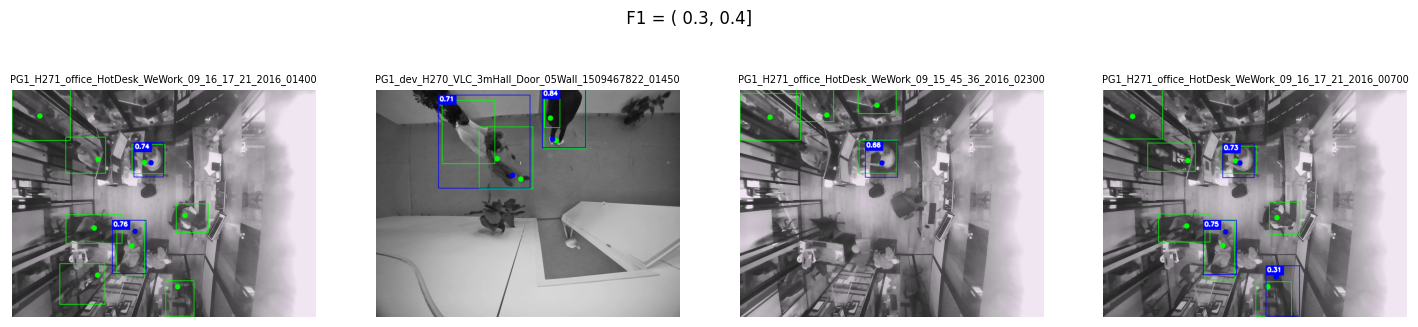

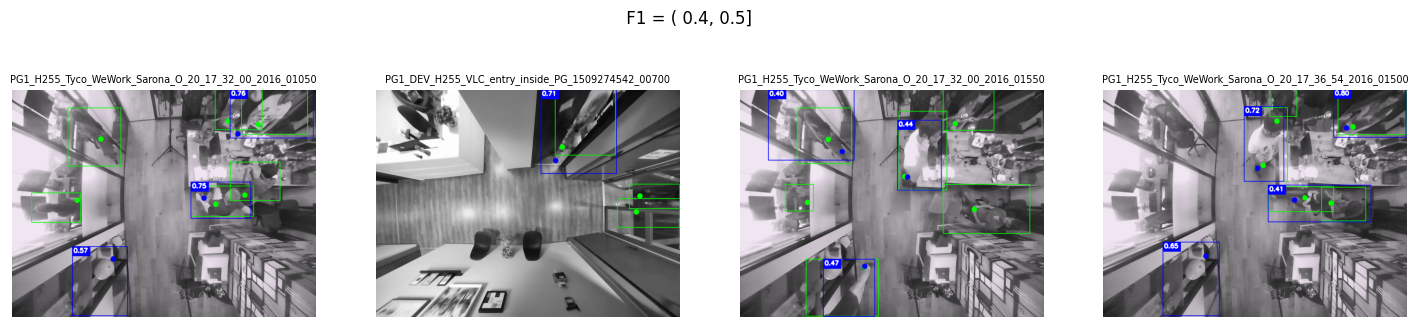

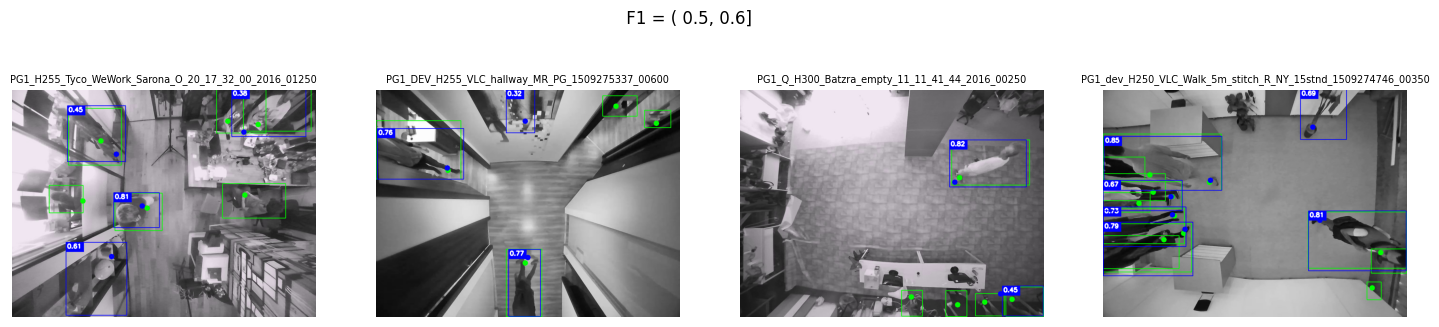

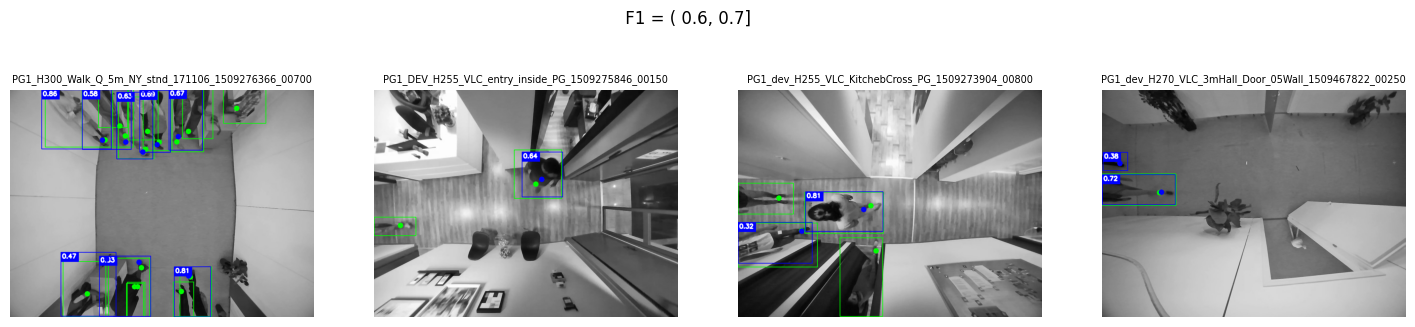

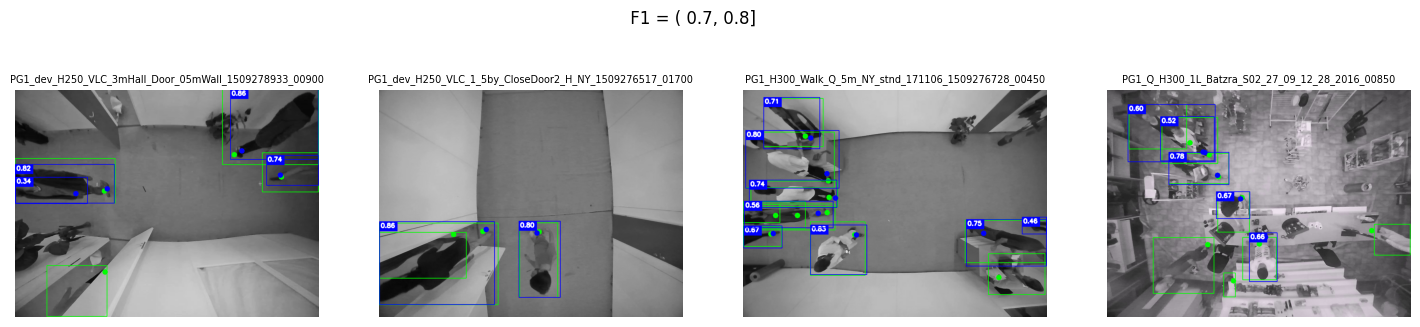

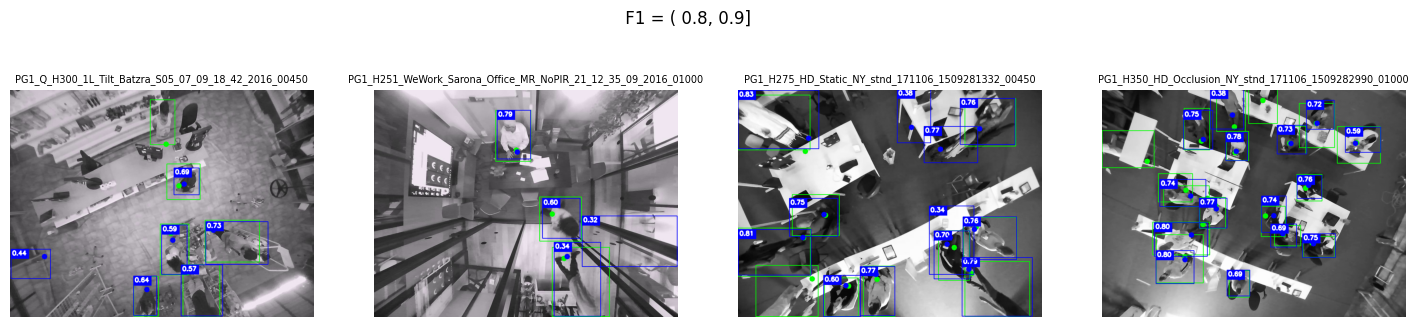

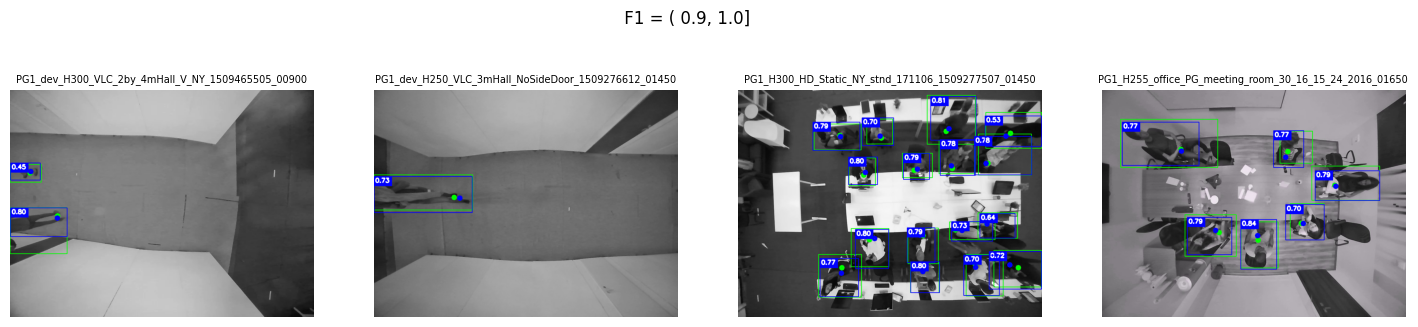

In [9]:
N = 4
ranges = np.arange(-0.1, 1.01, 0.1)
ranges

total_n = metrics.shape[0]
for i in range(len(ranges) - 1):
    img_ids = metrics[((metrics["F1"] > ranges[i])) & (metrics["F1"] <= ranges[i + 1])]["img_id"].values
    print(f"In interval ({ranges[i]:>4.01f}, {ranges[i + 1]:.01f}] number of cases = {img_ids.shape[0]:>4} ({img_ids.shape[0] / total_n * 100:>4.01f}%)")

    # np.random.seed(42)
    np.random.seed(11)
    np.random.shuffle(img_ids)
    
    plt.figure(figsize=(18, 4))
    plt.suptitle(f" F1 = ({ranges[i]:>4.01f}, {ranges[i + 1]:.01f}]")
    for i, img_id in enumerate(img_ids[:N]):
        plt.subplot(1, 4, i + 1)
        plt.imshow(plot_img(img_id, predictions_by_id))
        plt.title(img_id, fontsize=7)
        plt.axis('off');
